<a href="https://colab.research.google.com/github/IshanShivanshBangroo/ActivityPsyDT_JustInTimeAI/blob/main/IshanSBselective_generation_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Selective generation demo. Answer, ask or decline

IST 597-002 technical tutorial · Ishan Shivansh Bangroo

This notebook tests when an LLM application should release an answer. A small open model (Qwen2.5-1.5B-Instruct) answers 400 questions from the SQuAD 2.0 development set. Half of them have no answer in the passage. Each answer is gated by five confidence signals, and we measure **coverage** (share of questions answered) and **selective risk** (share of released answers that are wrong).

It also runs 12 constructed ambiguous questions, each with two clarified readings, and the six workshop questions from the class activity.

**Part 1** runs the model once and saves every output to `results_cache.jsonl`. It needs a GPU (Runtime > Change runtime type > T4 GPU) and takes about 15 to 25 minutes on a T4, longer if the float16 check fails and it falls back to float32. If the session drops, run it again and it continues where it stopped.

**Part 2** reads only the cache and computes every number and figure in a few seconds. It needs no GPU. In class, set `RUN_GENERATION = False` and run everything.

## Settings

In [1]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
K_SAMPLES = 10            # sampled answers per question, used for sample agreement and semantic entropy
TEMPERATURE = 1.0         # sampling temperature for those answers
MAX_NEW_TOKENS = 24       # answers are short phrases
SEED = 597
TARGET_COVERAGE = 0.5     # coverage at which the gates are compared
F1_CORRECT = 0.5          # an answer counts as correct if its token F1 with a gold answer is at least this
CACHE_PATH = "results_cache.jsonl"
RUN_GENERATION = True     # set to False to skip Part 1 and only read the cache

## Shared utilities

Answer scoring follows the official SQuAD 2.0 normalization (lower case, no punctuation, no articles). A reply counts as a **decline** if it says the passage does not give the answer.

In [2]:
import re, json, string, collections, math, random, os, time

_PUNCT = set(string.punctuation)

def normalize_answer(s):
    """Official SQuAD 2.0 normalization."""
    s = s.lower()
    s = "".join(ch for ch in s if ch not in _PUNCT)
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def token_f1(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    if not p or not g:
        return float(p == g)
    same = sum((collections.Counter(p) & collections.Counter(g)).values())
    if same == 0:
        return 0.0
    prec, rec = same / len(p), same / len(g)
    return 2 * prec * rec / (prec + rec)

def best_f1(pred, golds):
    return max((token_f1(pred, g) for g in golds), default=0.0)

def exact_match(pred, golds):
    return float(any(normalize_answer(pred) == normalize_answer(g) for g in golds))

NO_ANSWER_RE = re.compile(
    r"\bunanswerable\b"
    r"|\bnot (?:mentioned|stated|specified|provided|given|included|present|found|available|known|clear)\b"
    r"|\b(?:does|do|did)\s*n[o']t (?:say|mention|specify|state|provide|contain|include|indicate|give|tell)\b"
    r"|\bno (?:information|answer|mention|data)\b"
    r"|\bcan(?:not|'t| not) be (?:determined|answered|found)\b"
    r"|^\s*(?:unknown|none|n/?a)\s*\.?\s*$",
    re.IGNORECASE)

def is_no_answer(text):
    return bool(NO_ANSWER_RE.search(text or ""))

def clean_answer(text):
    """First non-empty line, without an 'Answer:' prefix, quotes or a trailing period."""
    lines = [l.strip() for l in (text or "").strip().splitlines() if l.strip()]
    t = lines[0] if lines else ""
    t = re.sub(r"^(?:final\s+)?answer\s*[:\-]\s*", "", t, flags=re.IGNORECASE)
    t = re.sub(r"[.;,]+$", "", t.strip())
    t = t.strip("\"'“”‘’").strip()
    return re.sub(r"[.;,]+$", "", t).strip()

def parse_confidence(text):
    """First number in the reply, read as a percentage. None if there is no usable number."""
    m = re.search(r"\d+(?:\.\d+)?", text or "")
    if not m:
        return None
    v = float(m.group(0))
    if "." in m.group(0) and v <= 1.0:
        v *= 100.0            # a reply such as 0.9
    return v / 100.0 if 0.0 <= v <= 100.0 else None

PROMPTS = {
    "forced": ("Answer the question using the passage. Reply with only the answer, a short phrase taken "
               "from the passage. Always give your best answer.\n\nPassage: {context}\n\nQuestion: {question}"),
    "abstain": ("Answer the question using the passage. Reply with only the answer, a short phrase taken "
                "from the passage. If the passage does not contain the answer, reply with only the word "
                "unanswerable.\n\nPassage: {context}\n\nQuestion: {question}"),
    "verbal": ("Passage: {context}\n\nQuestion: {question}\n\nProposed answer: {answer}\n\n"
               "How likely is it that the proposed answer is correct? Reply with only a number from 0 to 100."),
    "support": ("Passage: {context}\n\nQuestion: {question}\n\n"
                "Does the passage contain the answer to this question? Reply with only Yes or No."),
}

def make_prompt(kind, context, question, answer=None):
    return PROMPTS[kind].format(context=context, question=question, answer=answer)

try:
    display
except NameError:          # outside Jupyter
    display = print

# Part 1. Run the model once and save the cache

### Questions

The SQuAD 2.0 sample is fixed by question id (seed 597). The first half is the **calibration** half and the second half the **test** half, each with 100 answerable and 100 unanswerable questions. The file is checked against the SHA-256 hash of the copy used to draw the sample.

In [3]:
SQUAD_URL = "https://rajpurkar.github.io/SQuAD-explorer/dataset/dev-v2.0.json"
SQUAD_SHA256 = "80a5225e94905956a6446d296ca1093975c4d3b3260f1d6c8f68bc2ab77182d8"
SQUAD_IDS = {   # seed 597. Each half has 100 answerable and 100 unanswerable questions, in that order
    "calib": [
        "5710e8c8a58dae1900cd6b2a", "571cb010dd7acb1400e4c12a", "5725daa8ec44d21400f3d6b4", "572a0d21af94a219006aa786",
        "571097baa58dae1900cd6a9c", "57299326af94a219006aa516", "57281940ff5b5019007d9d47", "5725f8f5ec44d21400f3d7b1",
        "572fffb1b2c2fd14005686fa", "5726356938643c19005ad2ff", "5727e9523acd2414000def96", "572871bd3acd2414000dfa06",
        "572ffc99947a6a140053cef7", "57280e1aff5b5019007d9bee", "57286d4f2ca10214002da32a", "572fe393947a6a140053cdbc",
        "57265746dd62a815002e821c", "572a0b0b6aef0514001551f6", "5728f6446aef0514001548e7", "56e1ec83cd28a01900c67c0a",
        "572996c73f37b319004784b4", "5733d2dbd058e614000b633b", "5726eb4b5951b619008f826d", "5725fe63ec44d21400f3d7dd",
        "573011de04bcaa1900d770fa", "57306797396df919000960ef", "56e1c0f6cd28a01900c67b2e", "57111ab8a58dae1900cd6c3d",
        "572fc659b2c2fd1400568449", "56e1b62ecd28a01900c67aa3", "572faec7b2c2fd1400568335", "571cda1bdd7acb1400e4c197",
        "5725f7cd38643c19005acf24", "572867543acd2414000df9a3", "572985011d04691400779505", "5727d3843acd2414000ded6a",
        "570d4c3bfed7b91900d45e34", "57300580b2c2fd140056874f", "57286951ff5b5019007da20f", "571c9348dd7acb1400e4c115",
        "572861cc4b864d1900164962", "5710eca0a58dae1900cd6b3b", "57114e8d50c2381900b54a5e", "5727da564b864d1900163e8e",
        "56e1a0dccd28a01900c67a2e", "57273a465951b619008f8703", "5733d7cbd058e614000b63ab", "57263dcd89a1e219009ac5a5",
        "56dddf4066d3e219004dad5f", "572879574b864d1900164a14", "5705fd8475f01819005e7844", "5729f8516aef05140015516c",
        "57097051ed30961900e84136", "5729e2b76aef0514001550cf", "572a058aaf94a219006aa751", "5726534d708984140094c271",
        "5727e6cbff5b5019007d97ef", "57268527708984140094c8c0", "57274e975951b619008f87fa", "56e1dc62cd28a01900c67bce",
        "572885023acd2414000dfa83", "57297d421d046914007794e8", "5727490bdd62a815002e9a83", "56e1efa0e3433e140042321b",
        "5727dc473acd2414000dee45", "572ffc99947a6a140053cef6", "5726534d708984140094c270", "5730b4282461fd1900a9cfc5",
        "572686fc708984140094c8e6", "572f7b33947a6a140053c9a2", "57115f0a50c2381900b54aa7", "57108d69b654c5140001f987",
        "572677e7708984140094c723", "572667e2f1498d1400e8de92", "5727526cdd62a815002e9b10", "57286dfa2ca10214002da335",
        "5728659f4b864d190016498d", "5705e3f252bb89140068966e", "57273f27dd62a815002e9a0c", "572683f95951b619008f7529",
        "5728223cff5b5019007d9dc6", "572fdd03a23a5019007fcaa1", "5725f8f5ec44d21400f3d7b5", "5726398589a1e219009ac58a",
        "5729da0faf94a219006aa677", "57267ebfdd62a815002e872e", "57306797396df919000960f0", "5730a0778ab72b1400f9c60a",
        "572a07fc6aef0514001551df", "5728dddc2ca10214002da9d4", "57261f9f271a42140099d4aa", "573027d6a23a5019007fce9e",
        "572a1ba46aef051400155291", "57112686b654c5140001fbd6", "572982e66aef051400154f92", "57284d484b864d1900164900",
        "5725c28a271a42140099d14d", "57265f605951b619008f70dc", "5728e8212ca10214002daa6d", "57265aaf5951b619008f706c",
        "5ad23e1bd7d075001a4288b5", "5a592c9d3e1742001a15cfda", "5a66a156f038b7001ab0c072", "5ad3e83e604f3c001a3ff63c",
        "5a8933ed3b2508001a72a516", "5a668d4ef038b7001ab0bfc4", "5ad26839d7d075001a42925b", "5a550b52134fea001a0e1848",
        "5ad15a11645df0001a2d1857", "5a665338846392001a1e1ac7", "5ad4fd0f5b96ef001a10a896", "5a1c6968b4fb5d001871461b",
        "5ad55fe75b96ef001a10ad0f", "5ad3ad60604f3c001a3fec06", "5ad252e6d7d075001a428d0d", "5a8944653b2508001a72a57c",
        "5a3e488b378766001a00253e", "5ad3af11604f3c001a3fec63", "5acff3b377cf76001a6865fc", "5ad3f689604f3c001a3ff9e3",
        "5ad508665b96ef001a10aa69", "5a665549846392001a1e1ad5", "5ad4db615b96ef001a10a434", "5ad510be5b96ef001a10ab58",
        "5ad40cdb604f3c001a400092", "5ad4f3a25b96ef001a10a75c", "5ad28a57d7d075001a4299b2", "5ad0316a77cf76001a686de4",
        "5a57f0ea770dc0001aeefee5", "5ad4d55f5b96ef001a10a278", "5a25f38dc93d92001a40035b", "5ad22a96d7d075001a4285de",
        "5a0c677bf5590b0018dab3f0", "5ad21646d7d075001a4283c5", "5ad26964d7d075001a4292cc", "5a6ceb164eec6b001a80a6cb",
        "5ad25f42d7d075001a428f72", "5ad0316177cf76001a686dde", "5ad3bb12604f3c001a3feeb9", "5ad3ad60604f3c001a3fec07",
        "5ad40346604f3c001a3ffd74", "5ad40b9a604f3c001a40001b", "5a820c4931013a001a335146", "5ad3a076604f3c001a3fe9ab",
        "5ad03b7977cf76001a686ead", "5a7b12a421c2de001afe9d52", "5ad3e83e604f3c001a3ff63d", "5ad3a839604f3c001a3feaf2",
        "5ad0483977cf76001a686f8d", "5ad28ea7d7d075001a429a50", "5a2358cc82b03a001a4aa798", "5a6ce8ea4eec6b001a80a6b7",
        "5ad26235d7d075001a429080", "5ad4a049ba00c4001a268e43", "5ad4f8255b96ef001a10a810", "5ad24319d7d075001a4289d0",
        "5a580d05770dc0001aeeff98", "5ad4db9f5b96ef001a10a440", "5ad25e17d7d075001a428f16", "5ad3a27c604f3c001a3fea32",
        "5a55106f134fea001a0e18ae", "5ad3bd30604f3c001a3fef0f", "5a0c7edcf5590b0018dab43e", "5ad3c46a604f3c001a3fefb1",
        "5acfecc577cf76001a686510", "5ad25b1cd7d075001a428e67", "5ad042cf77cf76001a686f25", "5a551230134fea001a0e18cf",
        "5ad546c75b96ef001a10ac10", "5ad40b87604f3c001a400006", "5ad0312677cf76001a686dc9", "5a1c883cb4fb5d0018714670",
        "5acfa71b77cf76001a68572f", "5a82079731013a001a335120", "5a7b093b21c2de001afe9d0d", "5ad541ad5b96ef001a10abeb",
        "5a665549846392001a1e1ad9", "5ad40639604f3c001a3ffe4c", "5ad2605dd7d075001a428fc6", "5a67978ef038b7001ab0c309",
        "5ad0285977cf76001a686c0e", "5ad28614d7d075001a4298c2", "5a7b0ec521c2de001afe9d20", "5ad2424cd7d075001a42898a",
        "5ad2a71ad7d075001a429e02", "5ad2454cd7d075001a428a94", "5a637c6268151a001a922312", "5acfe73c77cf76001a6863d4",
        "5ad400f0604f3c001a3ffcf2", "5a57c667770dc0001aeefd66", "5ad265efd7d075001a4291d3", "5ad247b0d7d075001a428b46",
        "5a3e3de4378766001a002514", "5ad02bef77cf76001a686ca4", "5a57f0ea770dc0001aeefee2", "5ad28098d7d075001a4297b9",
        "5acf8d4077cf76001a6851f6", "5a66893ff038b7001ab0bf74", "5ad569c05b96ef001a10ae37", "5a81f84e31013a001a33500a"],
    "test": [
        "5729fa40af94a219006aa711", "57332c1e4776f4190066073b", "572758e0f1498d1400e8f6af", "5727f05b4b864d190016406a",
        "572684365951b619008f7540", "5727d4922ca10214002d977e", "572fbb04a23a5019007fc8f8", "572646655951b619008f6ec2",
        "57337ddc4776f41900660bbc", "572941273f37b319004781af", "5726ea985951b619008f8265", "57281ab63acd2414000df495",
        "571094b7a58dae1900cd6a68", "57265e97708984140094c3c3", "573028fa04bcaa1900d77289", "5725c0f289a1e219009abdf2",
        "572869b84b864d19001649ae", "57309ef18ab72b1400f9c601", "572849b4ff5b5019007da0f3", "5727fd123acd2414000df187",
        "57264efddd62a815002e8138", "56e1b8f3e3433e14004230e7", "572fae4b04bcaa1900d76be1", "571c91c8dd7acb1400e4c10e",
        "572885c44b864d1900164a7b", "571117d4a58dae1900cd6c0a", "5733fd66d058e614000b6735", "5727478cf1498d1400e8f59a",
        "56de16ca4396321400ee25c7", "572882242ca10214002da423", "572ff626947a6a140053ce8f", "57108198b654c5140001f93b",
        "57271f125951b619008f8639", "573003dd947a6a140053cf46", "5725b33f6a3fe71400b8952e", "57303048947a6a140053d255",
        "571117d4a58dae1900cd6c0b", "57096f37200fba1400367fe6", "5737534ec3c5551400e51eab", "5725cb33271a42140099d1db",
        "572995d46aef051400154fe8", "57287ddf3acd2414000dfa41", "57274712708984140094dbae", "572847dd4b864d19001648bd",
        "5730ac782461fd1900a9cf77", "5711619950c2381900b54aaf", "57286010ff5b5019007da1cd", "57376a1bc3c5551400e51ec4",
        "57105da9a58dae1900cd69a1", "57284b904b864d19001648e4", "5729fa40af94a219006aa70f", "571c3e8cdd7acb1400e4c0a6",
        "571cebc05efbb31900334e4b", "573009a004bcaa1900d7704f", "57340b1bd058e614000b6869", "571c3a685efbb31900334db5",
        "5730126ba23a5019007fcd0d", "573766251c45671900574473", "57273e50dd62a815002e9a02", "57113639a58dae1900cd6d1a",
        "5726415bec44d21400f3dcd4", "572a0bebaf94a219006aa772", "5737a9afc3c5551400e51f65", "572ffbaa947a6a140053cee6",
        "57106644b654c5140001f8e8", "56de1728cffd8e1900b4b5d7", "572940246aef051400154bec", "573314e3d058e614000b56f2",
        "57293d116aef051400154bcb", "5726ddf6f1498d1400e8ee08", "571c9074dd7acb1400e4c102", "57264e66dd62a815002e811b",
        "57060a1175f01819005e78d2", "5726da89dd62a815002e92b3", "572ff890a23a5019007fcbd0", "57268f2bf1498d1400e8e3c4",
        "57263ea0271a42140099d7c6", "57268d2ddd62a815002e894e", "57294209af94a219006aa201", "57308ddc396df919000961a8",
        "56e17e6ee3433e1400422f7f", "572a06af3f37b31900478668", "570d2d68fed7b91900d45cbc", "572683075951b619008f7516",
        "5725cfd0271a42140099d226", "5733140a4776f419006606e2", "573098f38ab72b1400f9c5d2", "572989846aef051400154fc4",
        "571c8eb9dd7acb1400e4c0f9", "57284b904b864d19001648e5", "572a1a5c6aef051400155284", "5733e5a14776f4190066145b",
        "57111428b654c5140001fb02", "57287c142ca10214002da3d1", "5733f5f24776f419006615c4", "570614ff52bb89140068988a",
        "5729727baf94a219006aa43b", "5726975c708984140094cb21", "5711669550c2381900b54adf", "5727500f708984140094dc01",
        "5a8203d431013a001a3350c2", "5ad25b1cd7d075001a428e66", "5ad27abcd7d075001a42962b", "5a7b402121c2de001afe9e0f",
        "5ad3ea79604f3c001a3ff6ea", "5a8373a7e60761001a2eb732", "5a23548782b03a001a4aa784", "5ad24a2ad7d075001a428bb8",
        "5ad1556e645df0001a2d17da", "5a0c6c78f5590b0018dab402", "5ad3f13e604f3c001a3ff867", "5ad02de177cf76001a686d16",
        "5a839654e60761001a2eb7f3", "5a7b34fa21c2de001afe9dc9", "5a3e539a378766001a00258b", "5ad3b3dc604f3c001a3fed67",
        "5ad0483977cf76001a686f8c", "5ad3c1ad604f3c001a3fef90", "5a38ab9fa4b263001a8c188a", "5ad254a5d7d075001a428d26",
        "5acfebe477cf76001a6864d9", "5a2c3595bfd06b001a5aea62", "5a665870846392001a1e1af3", "5a57c667770dc0001aeefd6a",
        "5ad29b43d7d075001a429bcc", "5ad3f4b1604f3c001a3ff952", "5ad4d8d65b96ef001a10a364", "5acfed0b77cf76001a686524",
        "5ad50de85b96ef001a10ab16", "5ad14816645df0001a2d1541", "5ad02e8277cf76001a686d51", "5acf9a5277cf76001a685420",
        "5a66978af038b7001ab0c02b", "5a67a1e3f038b7001ab0c389", "5ad2649ad7d075001a429161", "5a3e40d1378766001a002521",
        "5ad4f40c5b96ef001a10a775", "5a75028897ca42001a521db2", "5ad4cc135b96ef001a10a0f3", "5ad4f1365b96ef001a10a70e",
        "5ad02d3077cf76001a686cf8", "5a58cfd63e1742001a15ce33", "5ad507d25b96ef001a10aa4d", "5ad4da795b96ef001a10a3e9",
        "5ad141e1645df0001a2d1406", "5ad288e1d7d075001a429973", "5ad3ae4f604f3c001a3fec4a", "5a668d4ef038b7001ab0bfc2",
        "5acff6ea77cf76001a686682", "5ad248f7d7d075001a428b8c", "5acfe95877cf76001a686440", "5a667dae846392001a1e1c56",
        "5acfed5277cf76001a68652e", "5a1c8a1eb4fb5d0018714698", "5acf9a5277cf76001a68541c", "5ad3c57a604f3c001a3feff4",
        "5a0c6698f5590b0018dab3e5", "5ad14966645df0001a2d1582", "5a83894de60761001a2eb78d", "5a5915cd3e1742001a15cf77",
        "5a3e307f378766001a0024d8", "5acf9bcf77cf76001a68547c", "5ad0285977cf76001a686c0f", "5ad4f28c5b96ef001a10a734",
        "5ad25e99d7d075001a428f30", "5ad3f13e604f3c001a3ff865", "5ad24e50d7d075001a428c3a", "5ad3ad01604f3c001a3febd5",
        "5ad56bcd5b96ef001a10ae63", "5ad4d55f5b96ef001a10a274", "5a60556eeae51e001ab14d18", "5ad56bcd5b96ef001a10ae62",
        "5ad40158604f3c001a3ffd0d", "5ad01c8877cf76001a686a64", "5a7b33b821c2de001afe9dbf", "5a581bda770dc0001aef0002",
        "5a1c8092b4fb5d001871462e", "5a5915cd3e1742001a15cf78", "5a2eced7a83784001a7d24b3", "5ad2877cd7d075001a429915",
        "5a55068b134fea001a0e1810", "5ad3c57a604f3c001a3feff1", "5ad507d25b96ef001a10aa4c", "5ad26586d7d075001a4291b3",
        "5ad3bce5604f3c001a3feefe", "5acff4b177cf76001a686618", "5ad50bb95b96ef001a10aaaf", "5a551a65134fea001a0e191f",
        "5a83acb4e60761001a2eb862", "5a0c7fb2f5590b0018dab446", "5a38c34ea4b263001a8c190c", "5ad547945b96ef001a10ac1a",
        "5a668682f038b7001ab0bf52", "5a67b94bf038b7001ab0c444", "5ad14966645df0001a2d1583", "5ad407de604f3c001a3ffebf",
        "5ad153e9645df0001a2d1797", "5ad26278d7d075001a4290af", "5ad2647bd7d075001a42915a", "5ad2605dd7d075001a428fc9"],
}

def load_squad_items(path="dev-v2.0.json"):
    import hashlib, urllib.request
    by_id = {}
    try:
        if not os.path.exists(path):
            urllib.request.urlretrieve(SQUAD_URL, path)
        digest = hashlib.sha256(open(path, "rb").read()).hexdigest()
        print("SQuAD 2.0 dev file matches the copy used for the sample:", digest == SQUAD_SHA256)
        for art in json.load(open(path))["data"]:
            for para in art["paragraphs"]:
                for qa in para["qas"]:
                    by_id[qa["id"]] = dict(
                        context=para["context"], question=qa["question"], title=art["title"],
                        is_impossible=bool(qa.get("is_impossible", False)),
                        golds=sorted({a["text"] for a in qa["answers"]}),
                        plausible=sorted({a["text"] for a in qa.get("plausible_answers", [])}))
    except Exception as e:
        print("Direct download failed, using the Hugging Face copy instead:", e)
        from datasets import load_dataset
        for ex in load_dataset("rajpurkar/squad_v2", split="validation"):
            by_id[ex["id"]] = dict(context=ex["context"], question=ex["question"], title=ex["title"],
                                   is_impossible=len(ex["answers"]["text"]) == 0,
                                   golds=sorted(set(ex["answers"]["text"])), plausible=[])
    items = []
    for split in ("calib", "test"):
        for qid in SQUAD_IDS[split]:
            it = dict(by_id[qid])
            it.update(set="squad", id=qid, split=split)
            items.append(it)
    print(len(items), "SQuAD questions,", sum(it["is_impossible"] for it in items), "without an answer")
    return items

### Constructed questions

The workshop notice and its six questions are the class activity. The 12 ambiguous questions each have two valid readings, and each reading has a clarified question and a gold answer. For these the right action is to **ask**, which a gate with only answer and decline cannot do.

In [4]:
WORKSHOP_NOTICE = ("Coding workshop · Room 204 · Friday 14:00\n"
                   "Design workshop · Room 310 · Friday 16:00\n"
                   "Registration required. Bring a laptop.")

WORKSHOP_QUESTIONS = [   # id, worksheet label, question, gold answers, no answer in the notice
    ("w1", "Coding room?", "Which room is the coding workshop in?", ["204", "Room 204"], False),
    ("w2", "Design room?", "Which room is the design workshop in?", ["310", "Room 310"], False),
    ("w3", "Coding start time?", "What time does the coding workshop start?", ["14:00", "2 pm", "2:00 pm"], False),
    ("w4", "Design start time?", "What time does the design workshop start?", ["16:00", "4 pm", "4:00 pm"], False),
    ("w5", "Attendance fee?", "How much does it cost to attend the workshop?", [], True),
    ("w6", "Coding end time?", "What time does the coding workshop end?", [], True),
]

AMBIGUOUS = [   # id, notice, ambiguous question, (clarified question A, golds A), (clarified question B, golds B)
    ("a01", WORKSHOP_NOTICE, "Which room is the workshop in?",
     ("Which room is the coding workshop in?", ["204"]), ("Which room is the design workshop in?", ["310"])),
    ("a02", WORKSHOP_NOTICE, "What time does the workshop start?",
     ("What time does the coding workshop start?", ["14:00", "2 pm"]),
     ("What time does the design workshop start?", ["16:00", "4 pm"])),
    ("a03", "North Library opens at 09:00. South Library opens at 11:00. Both libraries close at 22:00.",
     "What time does the library open?",
     ("What time does North Library open?", ["09:00", "9:00", "9 am", "9am"]),
     ("What time does South Library open?", ["11:00", "11 am", "11am"])),
    ("a04", "The express train to Pittsburgh leaves from platform 3 at 7:15. "
            "The local train to Pittsburgh leaves from platform 5 at 7:40.",
     "Which platform does the train to Pittsburgh leave from?",
     ("Which platform does the express train to Pittsburgh leave from?", ["3"]),
     ("Which platform does the local train to Pittsburgh leave from?", ["5"])),
    ("a05", "The statistics midterm is on October 14 in Hall 1. The biology midterm is on October 16 in Hall 2.",
     "When is the midterm?",
     ("When is the statistics midterm?", ["October 14", "Oct 14"]),
     ("When is the biology midterm?", ["October 16", "Oct 16"])),
    ("a06", "Professor Lee holds office hours on Tuesday in Room 112. "
            "Professor Patel holds office hours on Thursday in Room 118.",
     "What day are office hours held?",
     ("What day does Professor Lee hold office hours?", ["Tuesday"]),
     ("What day does Professor Patel hold office hours?", ["Thursday"])),
    ("a07", "Bus 12 runs every 15 minutes on weekdays. Bus 30 runs every 40 minutes on weekdays.",
     "How often does the bus run on weekdays?",
     ("How often does Bus 12 run on weekdays?", ["15 minutes"]),
     ("How often does Bus 30 run on weekdays?", ["40 minutes"])),
    ("a08", "Student tickets for the concert cost $8. Standard tickets for the concert cost $14.",
     "How much does a ticket for the concert cost?",
     ("How much does a student ticket for the concert cost?", ["$8", "8"]),
     ("How much does a standard ticket for the concert cost?", ["$14", "14"])),
    ("a09", "The project proposal is due on September 20. The final report is due on December 12.",
     "When is the deadline?",
     ("When is the project proposal due?", ["September 20"]),
     ("When is the final report due?", ["December 12"])),
    ("a10", "The café on the first floor closes at 6 pm. The café in the library closes at 10 pm.",
     "What time does the café close?",
     ("What time does the café on the first floor close?", ["6 pm", "6pm", "18:00"]),
     ("What time does the café in the library close?", ["10 pm", "10pm", "22:00"])),
    ("a11", "Parking in Lot A costs $2 per hour. Parking in Lot B costs $5 per day.",
     "How much does parking cost?",
     ("How much does parking in Lot A cost?", ["$2 per hour", "2"]),
     ("How much does parking in Lot B cost?", ["$5 per day", "5"])),
    ("a12", "The planning meeting is in Room 4B at 10:00. The budget meeting is in Room 2A at 15:00.",
     "Where is the meeting?",
     ("Where is the planning meeting?", ["Room 4B", "4B"]),
     ("Where is the budget meeting?", ["Room 2A", "2A"])),
]

def constructed_items():
    items = []
    for qid, label, q, golds, impossible in WORKSHOP_QUESTIONS:
        items.append(dict(set="workshop", id=qid, label=label, context=WORKSHOP_NOTICE, question=q,
                          golds=golds, is_impossible=impossible, plausible=[], split=None))
    for qid, ctx, q, (qa, ga), (qb, gb) in AMBIGUOUS:
        items.append(dict(set="ambig", id=qid, context=ctx, question=q, golds=ga + gb, is_impossible=False,
                          plausible=[], split=None,
                          readings=[dict(label="A", question=qa, golds=ga), dict(label="B", question=qb, golds=gb)]))
    return items

### Model

The model loads in bfloat16 on GPUs that support it, and in float16 on a T4. A quick check runs first, and if float16 gives broken output the model reloads in float32 (slower but safe). Sampling settings are passed on every call, so the model's own default sampling settings are never used.

In [5]:
def load_model():
    global torch, tok, model, DEVICE, STOP_IDS, PAD_ID, YES_ID, NO_ID, DTYPE_NAME
    import torch
    import transformers
    from transformers import AutoTokenizer, AutoModelForCausalLM
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    if DEVICE == "cpu":
        print("No GPU found. Part 1 would take hours on a CPU. "
              "Use Runtime > Change runtime type > T4 GPU, then run again.")
    cap = torch.cuda.get_device_capability() if DEVICE == "cuda" else (0, 0)
    dtype = torch.bfloat16 if cap[0] >= 8 else (torch.float16 if DEVICE == "cuda" else torch.float32)
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)

    def _load(dt):
        m = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
        m = m.to(device=DEVICE, dtype=dt).eval()
        gc = m.generation_config          # neutral defaults, so nothing is applied silently
        gc.do_sample, gc.temperature, gc.top_p, gc.top_k, gc.repetition_penalty = False, 1.0, 1.0, 50, 1.0
        return m

    model = _load(dtype)
    eos = model.generation_config.eos_token_id
    STOP_IDS = set(eos if isinstance(eos, (list, tuple)) else [eos])
    for t in ("<|im_end|>", "<|endoftext|>"):
        tid = tok.convert_tokens_to_ids(t)
        if isinstance(tid, int) and tid >= 0 and tid != tok.unk_token_id:
            STOP_IDS.add(tid)
    PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else min(STOP_IDS)
    YES_ID = tok.encode("Yes", add_special_tokens=False)[0]
    NO_ID = tok.encode("No", add_special_tokens=False)[0]
    DTYPE_NAME = str(dtype).replace("torch.", "")
    if not sanity_check():
        print("Output looked broken in", DTYPE_NAME, "so the model is reloading in float32.")
        model = _load(torch.float32)
        DTYPE_NAME = "float32"
        assert sanity_check(), "The model still gives broken output. Check the runtime and the model name."
    gpu = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"
    print(f"Loaded {MODEL_NAME} on {gpu} in {DTYPE_NAME}. torch {torch.__version__}, "
          f"transformers {transformers.__version__}")

def chat_ids(user_text):
    text = tok.apply_chat_template([{"role": "user", "content": user_text}],
                                   tokenize=False, add_generation_prompt=True)
    return tok(text, return_tensors="pt", add_special_tokens=False).input_ids.to(DEVICE)

def _until_stop(ids):
    out = []
    for t in ids:
        if t in STOP_IDS or t == PAD_ID:
            break
        out.append(t)
    return out

def generate(ids, n=1, sample=False, max_new_tokens=MAX_NEW_TOKENS, seed=None):
    """Returns n lists of generated token ids, cut at the first stop token."""
    kw = dict(max_new_tokens=max_new_tokens, num_return_sequences=n, pad_token_id=PAD_ID,
              eos_token_id=sorted(STOP_IDS), repetition_penalty=1.0)
    if sample:
        if seed is not None:
            torch.manual_seed(seed)
        kw.update(do_sample=True, temperature=TEMPERATURE, top_p=1.0, top_k=0)   # plain sampling
    else:
        kw.update(do_sample=False)                                               # greedy
    with torch.no_grad():
        out = model.generate(input_ids=ids, attention_mask=torch.ones_like(ids), **kw)
    return [_until_stop(row[ids.shape[1]:].tolist()) for row in out]

def text_of(token_ids):
    return tok.decode(token_ids, skip_special_tokens=True)

def answer_logprob(prompt_ids, answer_ids):
    """Sum of log-probabilities of the answer tokens given the prompt (one teacher-forced pass)."""
    if len(answer_ids) == 0:
        return float("nan"), 0
    a = torch.tensor([answer_ids], device=DEVICE)
    full = torch.cat([prompt_ids, a], dim=1)
    with torch.no_grad():
        logits = model(input_ids=full).logits[0, prompt_ids.shape[1] - 1: full.shape[1] - 1].float()
    lp = torch.log_softmax(logits, dim=-1).gather(1, a[0].unsqueeze(1)).squeeze(1)
    return float(lp.sum()), len(answer_ids)

def p_yes(prompt_ids):
    """P(Yes) / (P(Yes) + P(No)) for the first reply token."""
    with torch.no_grad():
        logits = model(input_ids=prompt_ids).logits[0, -1].float()
    pair = torch.stack([logits[YES_ID], logits[NO_ID]])
    return float(torch.softmax(pair, dim=0)[0])

def sanity_check():
    reply = text_of(generate(chat_ids("What is 2 + 3? Reply with only the number."), max_new_tokens=6)[0])
    py = p_yes(chat_ids("Is snow usually white? Reply with only Yes or No."))
    ok = ("5" in reply) and math.isfinite(py) and py > 0.5
    print(f"Sanity check. 2 + 3 -> {reply!r}, P(Yes) for 'Is snow usually white?' = {py:.3f}, ok = {ok}")
    return ok

### Generation

For every question the model produces, in this order:

1. a **greedy answer** to the always-answer prompt, the candidate that every gate decides on,
2. the **token probability** of that answer (geometric mean over its tokens),
3. **10 sampled answers** to the same prompt, for sample agreement and semantic entropy,
4. a **verbalized confidence** (0 to 100) for the greedy answer, asked in a second turn,
5. a **support self-check**, the probability that it answers Yes to "Does the passage contain the answer?",
6. a greedy answer to a prompt that **allows the reply unanswerable**, the model's own abstention.

For the ambiguous questions it also answers each clarified reading (one greedy answer and 10 samples).

In [6]:
def run_item(context, question, seed):
    f_ids = chat_ids(make_prompt("forced", context, question))
    g = generate(f_ids)[0]
    forced_raw = text_of(g)
    forced = clean_answer(forced_raw)
    lp_sum, ntok = answer_logprob(f_ids, g)
    samples = [clean_answer(text_of(s)) for s in generate(f_ids, n=K_SAMPLES, sample=True, seed=seed)]
    v_raw = text_of(generate(chat_ids(make_prompt("verbal", context, question, forced)), max_new_tokens=8)[0])
    support = p_yes(chat_ids(make_prompt("support", context, question)))
    a_raw = text_of(generate(chat_ids(make_prompt("abstain", context, question)))[0])
    return dict(forced=forced, forced_raw=forced_raw, forced_lp_sum=lp_sum, forced_ntok=ntok,
                samples=samples, verbal_raw=v_raw.strip(), verbal=parse_confidence(v_raw),
                support_p_yes=support, abstain=clean_answer(a_raw), abstain_raw=a_raw)

def run_readings(item, seed):
    for j, rd in enumerate(item["readings"]):
        r_ids = chat_ids(make_prompt("forced", item["context"], rd["question"]))
        rd["forced"] = clean_answer(text_of(generate(r_ids)[0]))
        rd["samples"] = [clean_answer(text_of(s))
                         for s in generate(r_ids, n=K_SAMPLES, sample=True, seed=seed + 1 + j)]

def meta_record(n_items):
    import transformers
    return dict(set="meta", id="meta", model=MODEL_NAME, dtype=DTYPE_NAME,
                device=torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
                torch=torch.__version__, transformers=transformers.__version__,
                k_samples=K_SAMPLES, temperature=TEMPERATURE, max_new_tokens=MAX_NEW_TOKENS, seed=SEED,
                n_items=n_items, prompts=PROMPTS,
                started_utc=time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime()))

def run_generation():
    items = load_squad_items() + constructed_items()
    index = {(it["set"], it["id"]): i for i, it in enumerate(items)}
    done = set()
    if os.path.exists(CACHE_PATH):
        for line in open(CACHE_PATH):
            if line.strip():
                r = json.loads(line)
                done.add((r.get("set"), r.get("id")))
    todo = [it for it in items if (it["set"], it["id"]) not in done]
    print(f"{len(items)} items, {len(items) - len(todo)} already in the cache, {len(todo)} to run")
    if not todo:
        return
    load_model()
    t0 = time.time()
    with open(CACHE_PATH, "a") as f:
        if ("meta", "meta") not in done:
            f.write(json.dumps(meta_record(len(items))) + "\n")
        for i, it in enumerate(todo):
            seed = SEED * 100000 + 10 * index[(it["set"], it["id"])]
            rec = dict(it)
            rec.update(run_item(it["context"], it["question"], seed))
            if it["set"] == "ambig":
                run_readings(rec, seed)
            f.write(json.dumps(rec) + "\n")
            f.flush()
            if (i + 1) % 20 == 0 or i + 1 == len(todo):
                rate = (time.time() - t0) / (i + 1)
                print(f"{i + 1}/{len(todo)} done, {rate:.1f} s per item, "
                      f"about {rate * (len(todo) - i - 1) / 60:.0f} min left")
    print("Saved", CACHE_PATH)

if RUN_GENERATION:
    run_generation()

SQuAD 2.0 dev file matches the copy used for the sample: True
400 SQuAD questions, 200 without an answer
418 items, 0 already in the cache, 418 to run


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Sanity check. 2 + 3 -> '5', P(Yes) for 'Is snow usually white?' = 1.000, ok = True
Loaded Qwen/Qwen2.5-1.5B-Instruct on Tesla T4 in float16. torch 2.11.0+cu130, transformers 5.18.0
20/418 done, 1.3 s per item, about 9 min left
40/418 done, 1.7 s per item, about 11 min left
60/418 done, 1.9 s per item, about 11 min left
80/418 done, 1.8 s per item, about 10 min left
100/418 done, 1.7 s per item, about 9 min left
120/418 done, 1.7 s per item, about 8 min left
140/418 done, 1.7 s per item, about 8 min left
160/418 done, 1.6 s per item, about 7 min left
180/418 done, 1.6 s per item, about 6 min left
200/418 done, 1.6 s per item, about 6 min left
220/418 done, 1.6 s per item, about 5 min left
240/418 done, 1.6 s per item, about 5 min left
260/418 done, 1.6 s per item, about 4 min left
280/418 done, 1.6 s per item, about 4 min left
300/418 done, 1.6 s per item, about 3 min left
320/418 done, 1.6 s per item, about 3 min left
340/418 done, 1.6 s per item, about 2 min left
360/418 done, 1.6 s p

Download the cache so you have it outside this session. Mounting Google Drive and copying the file there also works.

In [7]:
if RUN_GENERATION:
    try:
        from google.colab import files
        files.download(CACHE_PATH)
    except Exception as e:
        print("Not in Colab, the cache is at", os.path.abspath(CACHE_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 2. Results from the cache

Everything below reads only `results_cache.jsonl`. In a fresh session, run the Settings and Shared utilities cells first. If the cache is not in the working folder, the next cell asks you to upload it.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

def load_cache(path=CACHE_PATH):
    if not os.path.exists(path):
        from google.colab import files
        print("Upload results_cache.jsonl")
        path = next(iter(files.upload()))
    recs = [json.loads(l) for l in open(path) if l.strip()]
    meta = next((r for r in recs if r.get("set") == "meta"), {})
    by_key = {}
    for r in recs:                       # a resumed run can repeat an item, keep the last copy
        if r.get("set") != "meta":
            by_key[(r["set"], r["id"])] = r
    return meta, list(by_key.values())

META, RECS = load_cache()
print(f"Model {META.get('model')} ({META.get('dtype')}) on {META.get('device')}, "
      f"{META.get('k_samples')} samples at temperature {META.get('temperature')}, run started {META.get('started_utc')} UTC")
print(collections.Counter(r["set"] for r in RECS))

Model Qwen/Qwen2.5-1.5B-Instruct (float16) on Tesla T4, 10 samples at temperature 1.0, run started 2026-10-09 06:17:22 UTC
Counter({'squad': 400, 'ambig': 12, 'workshop': 6})


### Labels and signals

A **released** answer is wrong if the question has no answer in the passage, or if its token F1 with every gold answer is below 0.5. A reply that declines is never released. Every signal is oriented so that a higher value means more confident.

* **Token probability**, the geometric mean probability of the greedy answer's tokens.
* **Verbalized confidence**, the number the model states, divided by 100.
* **Sample agreement**, the share of the 10 sampled answers that match the greedy answer (token F1 at least 0.5).
* **Semantic entropy**, entropy of the 10 samples after grouping answers that match (token F1 at least 0.5). Shown negated, so higher is more confident. Grouping uses word overlap, not the entailment model of Farquhar et al. (2024).
* **Support self-check**, the model's probability of Yes to "Does the passage contain the answer?" It looks at the passage, not at the answer, so it targets unanswerable questions.

In [9]:
def agreement(ref, samples):
    return float(np.mean([token_f1(s, ref) >= 0.5 for s in samples])) if samples else float("nan")

def overlap_clusters(texts, thr=0.5):
    reps, labels = [], []
    for t in texts:
        key = "<declined>" if is_no_answer(t) else t
        for ci, rep in enumerate(reps):
            if (key == rep == "<declined>") or ("<declined>" not in (key, rep) and token_f1(key, rep) >= thr):
                labels.append(ci)
                break
        else:
            reps.append(key)
            labels.append(len(reps) - 1)
    return labels, reps

def entropy_bits(counts):
    p = np.asarray(counts, dtype=float)
    p = p[p > 0] / p.sum()
    return float(-(p * np.log2(p)).sum())

def sample_entropy(samples):
    labels, _ = overlap_clusters(samples)
    return entropy_bits(list(collections.Counter(labels).values()))

def item_row(r):
    f = r["forced"]
    golds = r["golds"]
    imp = bool(r["is_impossible"])
    eligible = not is_no_answer(f)
    wrong = imp or best_f1(f, golds) < F1_CORRECT
    a = r["abstain"]
    ntok = r.get("forced_ntok") or 0
    return dict(
        set=r["set"], id=r["id"], split=r.get("split"), question=r["question"], answer=f,
        answerable=not imp, eligible=eligible, wrong=wrong, correct=eligible and not wrong,
        wrong_em=imp or exact_match(f, golds) == 0,
        matches_distractor=imp and best_f1(f, r.get("plausible", [])) >= 0.5,
        tokprob=math.exp(r["forced_lp_sum"] / ntok) if ntok else float("nan"),
        verbal=r["verbal"] if r["verbal"] is not None else float("nan"),
        agree=agreement(f, r["samples"]),
        neg_entropy=-sample_entropy(r["samples"]),
        support=r["support_p_yes"],
        abst_released=not is_no_answer(a),
        abst_wrong=imp or best_f1(a, golds) < F1_CORRECT)

df = pd.DataFrame([item_row(r) for r in RECS if r["set"] == "squad"])
SIGNALS = {"Token probability": "tokprob", "Verbalized confidence": "verbal",
           "Sample agreement": "agree", "Semantic entropy": "neg_entropy", "Support self-check": "support"}

n_ans, n_imp = int(df.answerable.sum()), int((~df.answerable).sum())
print(f"{len(df)} questions, {n_ans} answerable, {n_imp} without an answer")
print(f"Always-answer prompt. Declined on its own: {int((~df.eligible).sum())}. "
      f"Correct on answerable questions (F1 >= {F1_CORRECT}): {df[df.answerable].correct.mean():.1%}. "
      f"Exact match on answerable: {1 - df[df.answerable].wrong_em.mean():.1%}")
print(f"On questions without an answer it gave an answer {df[~df.answerable].eligible.mean():.1%} of the time, "
      f"and {df[~df.answerable].matches_distractor.mean():.1%} matched the planted distractor answer")
print(f"Verbalized confidence could not be read for {df.verbal.isna().sum()} of {len(df)} replies")

400 questions, 200 answerable, 200 without an answer
Always-answer prompt. Declined on its own: 1. Correct on answerable questions (F1 >= 0.5): 88.5%. Exact match on answerable: 75.0%
On questions without an answer it gave an answer 99.5% of the time, and 57.5% matched the planted distractor answer
Verbalized confidence could not be read for 0 of 400 replies


### Gates at matched coverage

Each gate releases the answers it scores highest until it has answered half of the questions (`TARGET_COVERAGE`). When several answers share the same score at the cut, the numbers are the expected result of picking among them at random, so no gate gains from how ties happen to be ordered. Intervals are 95% bootstrap intervals over questions (2,000 resamples).

* **Coverage**, share of all questions answered.
* **Wrong among released**, selective risk.
* **Correct answers withheld**, share of the questions the always-answer reply got right that the policy did not answer. This is the cost of declining.
* **Answerable declined**, share of questions that do have an answer which the policy did not answer, right or wrong.

The oracle row knows which questions have an answer and releases exactly those. It shows the best a perfect support check could do with this model's answers.

In [10]:
def _sorted_groups(scores, eligible):
    """Eligible items sorted by score (high first), with tie groups."""
    s = np.asarray(scores, dtype=float).copy()
    s[np.isnan(s)] = -np.inf
    idx = np.flatnonzero(eligible)
    idx = idx[np.argsort(-s[idx], kind="mergesort")]
    groups, i = [], 0
    while i < len(idx):
        j = i
        while j < len(idx) and s[idx[j]] == s[idx[i]]:
            j += 1
        groups.append(idx[i:j])
        i = j
    return groups

def expected_release(scores, eligible, k):
    """Expected 0/1 release indicator per item when the top k eligible items are released, ties at random."""
    rel = np.zeros(len(eligible))
    taken = 0
    for g in _sorted_groups(scores, eligible):
        if taken >= k:
            break
        take = min(len(g), k - taken)
        rel[g] = take / len(g)
        taken += take
    return rel

def policy_metrics(rel, wrong, answerable, correct):
    """rel is the (expected) release indicator per question. correct marks questions whose
    always-answer reply is right, so correct_withheld is the share of good answers a policy gives up."""
    rel = np.asarray(rel, dtype=float)
    released = rel.sum()
    return dict(coverage=released / len(rel),
                risk=float((rel * wrong).sum() / released) if released > 0 else float("nan"),
                answerable_declined=float(1 - (rel * answerable).sum() / answerable.sum()),
                correct_withheld=float(1 - (rel * correct).sum() / correct.sum()) if correct.sum() else float("nan"))

def all_policies(d, target=TARGET_COVERAGE):
    wrong, ans, elig = d.wrong.values.astype(float), d.answerable.values.astype(float), d.eligible.values
    corr = d.correct.values.astype(float)
    k = int(round(target * len(d)))
    out = {"Always answer": policy_metrics(elig.astype(float), wrong, ans, corr)}
    for name, col in SIGNALS.items():
        out[name + " gate"] = policy_metrics(expected_release(d[col].values, elig, k), wrong, ans, corr)
    out["Prompt allows 'unanswerable'"] = policy_metrics(d.abst_released.values.astype(float),
                                                         d.abst_wrong.values.astype(float), ans, corr)
    out["Oracle (knows which questions have an answer)"] = policy_metrics(
        (elig & d.answerable.values).astype(float), wrong, ans, corr)
    return out

def bootstrap_policies(d, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    draws = collections.defaultdict(lambda: collections.defaultdict(list))
    for _ in range(n_boot):
        b = d.iloc[rng.integers(0, len(d), len(d))].reset_index(drop=True)
        for pol, m in all_policies(b).items():
            for key, v in m.items():
                draws[pol][key].append(v)
    return draws

point = all_policies(df)
boot = bootstrap_policies(df)

def ci(pol, key):
    lo, hi = np.nanpercentile(boot[pol][key], [2.5, 97.5])
    return lo, hi

rows = []
for pol, m in point.items():
    lo, hi = ci(pol, "risk")
    rows.append({"Policy": pol, "Coverage": f"{m['coverage']:.0%}",
                 "Wrong among released": f"{m['risk']:.1%} [{lo:.1%}, {hi:.1%}]",
                 "Correct answers withheld": f"{m['correct_withheld']:.1%}",
                 "Answerable declined": f"{m['answerable_declined']:.1%}"})
main_table = pd.DataFrame(rows)
display(main_table)

,Policy,Coverage,Wrong among released,Correct answers withheld,Answerable declined
0,Always answer,100%,"55.6% [50.7%, 60.6%]",0.0%,0.0%
1,Token probability gate,50%,"46.0% [39.0%, 53.0%]",39.0%,43.0%
2,Verbalized confidence gate,50%,"38.9% [32.1%, 45.4%]",31.0%,33.2%
3,Sample agreement gate,50%,"41.6% [35.4%, 48.1%]",34.0%,39.5%
4,Semantic entropy gate,50%,"41.5% [35.2%, 47.7%]",33.9%,39.4%
5,Support self-check gate,50%,"26.8% [20.1%, 34.2%]",17.3%,18.3%
6,Prompt allows 'unanswerable',91%,"51.8% [46.3%, 57.2%]",0.0%,0.0%
7,Oracle (knows which questions have an answer),50%,"11.5% [7.1%, 16.1%]",0.0%,0.0%


Paired differences in selective risk at matched coverage (gate minus always answer, and between gates), with 95% bootstrap intervals from the same resamples. An interval that excludes zero is a difference this sample supports.

In [11]:
def paired(p1, p2, key="risk"):
    d = np.asarray(boot[p1][key]) - np.asarray(boot[p2][key])
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    return point[p1][key] - point[p2][key], lo, hi

gates = [g + " gate" for g in SIGNALS]
pairs = [(g, "Always answer") for g in gates]
best = min(gates, key=lambda g: point[g]["risk"])
pairs += [(g, best) for g in gates if g != best]
display(pd.DataFrame([{"Comparison": f"{a} minus {b}",
                       "Difference in wrong among released": f"{d:+.1%} [{lo:+.1%}, {hi:+.1%}]"}
                      for (a, b) in pairs for (d, lo, hi) in [paired(a, b)]]))

,Comparison,Difference in wrong among released
0,Token probability gate minus Always answer,"-9.6% [-14.4%, -5.0%]"
1,Verbalized confidence gate minus Always answer,"-16.7% [-20.8%, -12.7%]"
2,Sample agreement gate minus Always answer,"-14.0% [-18.0%, -10.3%]"
3,Semantic entropy gate minus Always answer,"-14.1% [-18.1%, -10.2%]"
4,Support self-check gate minus Always answer,"-28.8% [-32.8%, -24.8%]"
5,Token probability gate minus Support self-chec...,"+19.2% [+13.0%, +25.0%]"
6,Verbalized confidence gate minus Support self-...,"+12.1% [+7.1%, +17.0%]"
7,Sample agreement gate minus Support self-check...,"+14.8% [+9.3%, +20.2%]"
8,Semantic entropy gate minus Support self-check...,"+14.7% [+9.1%, +20.2%]"


### Risk-coverage curves and ranking quality

The curve shows selective risk at every coverage level. AURC is the mean selective risk over all coverage levels the gate can reach (lower is better). AUROC asks how well the signal separates correct from wrong released answers (0.5 is chance).

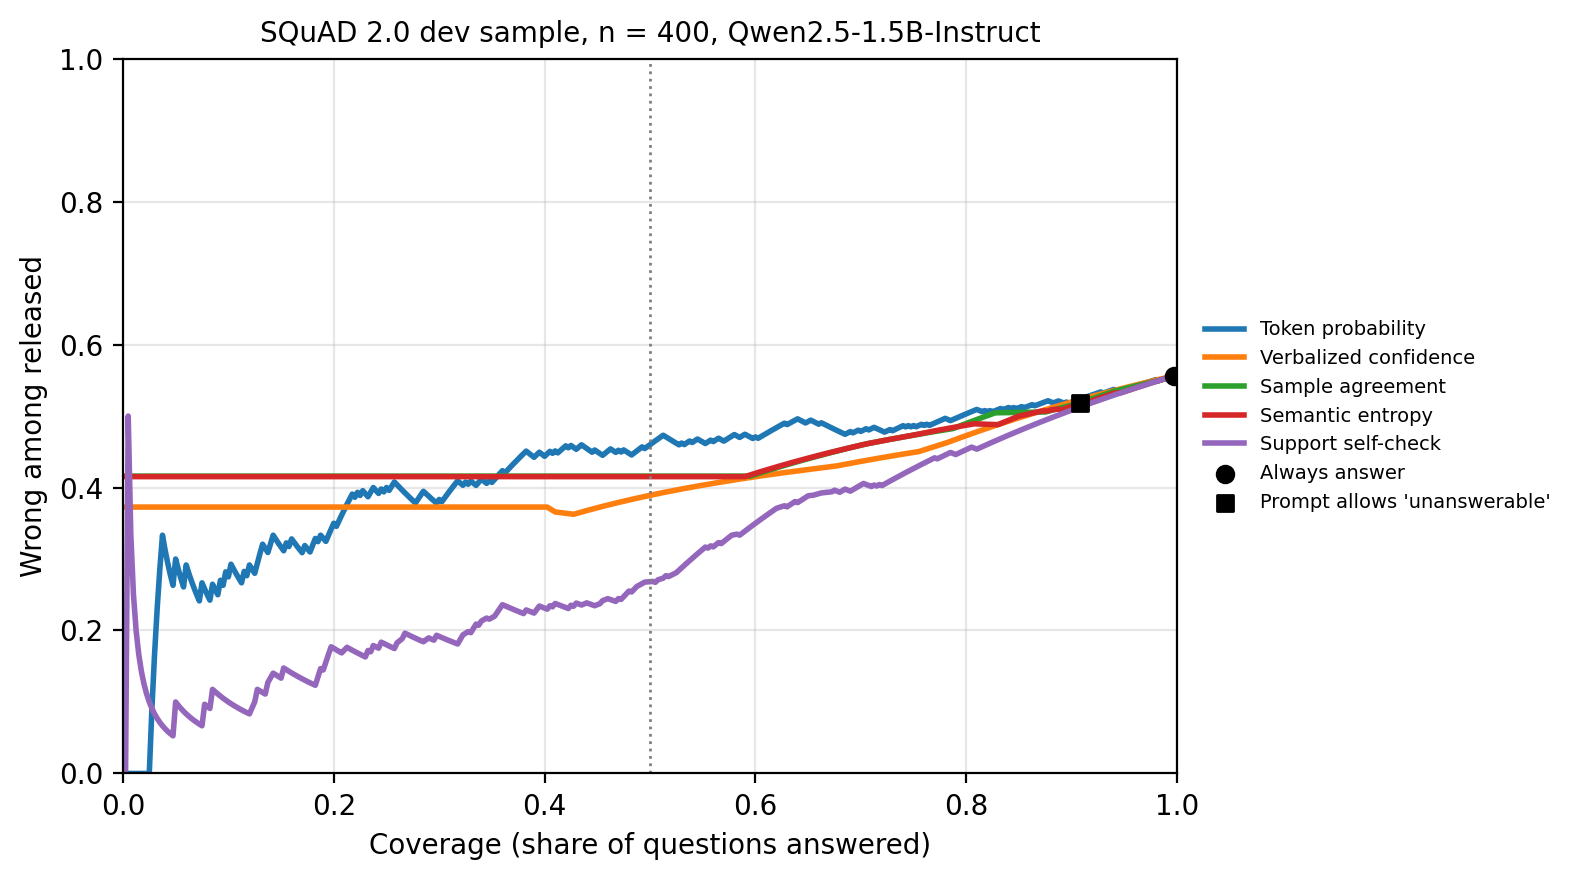

,Signal,AURC,"AUROC, correct vs wrong"
0,Token probability,"0.425 [0.370, 0.489]",0.659
1,Verbalized confidence,"0.418 [0.358, 0.477]",0.721
2,Sample agreement,"0.445 [0.393, 0.498]",0.684
3,Semantic entropy,"0.444 [0.389, 0.500]",0.687
4,Support self-check,"0.300 [0.251, 0.359]",0.856


In [12]:
def rc_curve(scores, eligible, wrong, n_total):
    cov, risk = [], []
    taken, wsum = 0, 0.0
    for g in _sorted_groups(scores, eligible):
        wb = wrong[g].sum()
        for t in range(1, len(g) + 1):
            cov.append((taken + t) / n_total)
            risk.append((wsum + t * wb / len(g)) / (taken + t))
        taken += len(g)
        wsum += wb
    return np.array(cov), np.array(risk)

wrong_arr = df.wrong.values.astype(float)
elig = df.eligible.values
quality = []
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=200)
for name, col in SIGNALS.items():
    cov, risk = rc_curve(df[col].values, elig, wrong_arr, len(df))
    ax.plot(cov, risk, lw=2, label=name)
    m = elig & ~np.isnan(df[col].values)
    y = (~df.wrong.values[m]).astype(int)
    auroc = roc_auc_score(y, df[col].values[m]) if 0 < y.sum() < len(y) else float("nan")
    aurc_b = [rc_curve(b[col].values, b.eligible.values, b.wrong.values.astype(float), len(b))[1].mean()
              for b in (df.iloc[np.random.default_rng(SEED + i).integers(0, len(df), len(df))].reset_index(drop=True)
                        for i in range(300))]
    quality.append({"Signal": name, "AURC": f"{risk.mean():.3f} [{np.percentile(aurc_b, 2.5):.3f}, "
                    f"{np.percentile(aurc_b, 97.5):.3f}]", "AUROC, correct vs wrong": f"{auroc:.3f}"})
aa = point["Always answer"]
ab = point["Prompt allows 'unanswerable'"]
ax.scatter([aa["coverage"]], [aa["risk"]], color="black", zorder=5, label="Always answer")
ax.scatter([ab["coverage"]], [ab["risk"]], color="black", marker="s", zorder=5, label="Prompt allows 'unanswerable'")
ax.axvline(TARGET_COVERAGE, color="grey", lw=1, ls=":")
ax.set_xlabel("Coverage (share of questions answered)")
ax.set_ylabel("Wrong among released")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"SQuAD 2.0 dev sample, n = {len(df)}, {META.get('model', '').split('/')[-1]}", fontsize=10)
ax.legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("risk_coverage.png", facecolor="white", bbox_inches="tight")
plt.show()
display(pd.DataFrame(quality))

### Thresholds set on the calibration half

A deployed gate needs a fixed threshold. Here each threshold is set on the calibration half to reach 50% coverage there, then applied unchanged to the test half. If a tie sits at the threshold, tied answers are released with the probability that hits the target on the calibration half.

In [13]:
def threshold_from(scores, eligible, n_total, target):
    s = np.where(np.isnan(scores), -np.inf, scores)[eligible]
    s = np.sort(s)[::-1]
    k = int(round(target * n_total))
    if k == 0 or len(s) == 0:
        return np.inf, 0.0
    tau = s[min(k, len(s)) - 1]
    n_gt, n_eq = int((s > tau).sum()), int((s == tau).sum())
    return tau, (min(k, len(s)) - n_gt) / n_eq

def apply_threshold(scores, eligible, tau, q):
    s = np.where(np.isnan(scores), -np.inf, scores)
    return np.where(s > tau, 1.0, np.where(s == tau, q, 0.0)) * eligible

cal, tst = df[df.split == "calib"], df[df.split == "test"]
rng = np.random.default_rng(SEED)
held = []
for name, col in SIGNALS.items():
    tau, q = threshold_from(cal[col].values, cal.eligible.values, len(cal), TARGET_COVERAGE)
    m = policy_metrics(apply_threshold(tst[col].values, tst.eligible.values, tau, q),
                       tst.wrong.values.astype(float), tst.answerable.values.astype(float),
                       tst.correct.values.astype(float))
    bs = []
    for _ in range(2000):
        b = tst.iloc[rng.integers(0, len(tst), len(tst))]
        bs.append(policy_metrics(apply_threshold(b[col].values, b.eligible.values, tau, q),
                                 b.wrong.values.astype(float), b.answerable.values.astype(float),
                                 b.correct.values.astype(float))["risk"])
    lo, hi = np.nanpercentile(bs, [2.5, 97.5])
    held.append({"Gate": name, "Threshold": round(float(tau), 3), "Test coverage": f"{m['coverage']:.0%}",
                 "Test wrong among released": f"{m['risk']:.1%} [{lo:.1%}, {hi:.1%}]",
                 "Test correct answers withheld": f"{m['correct_withheld']:.1%}"})
display(pd.DataFrame(held))

,Gate,Threshold,Test coverage,Test wrong among released,Test correct answers withheld
0,Token probability,0.929,49%,"43.9% [34.5%, 54.1%]",36.8%
1,Verbalized confidence,0.850,53%,"40.5% [32.5%, 49.6%]",27.4%
2,Sample agreement,1.000,47%,"38.3% [29.8%, 47.2%]",33.7%
3,Semantic entropy,0.000,48%,"38.3% [29.7%, 47.0%]",32.6%
4,Support self-check,0.890,51%,"28.4% [20.0%, 37.4%]",16.1%


### Calibration of verbalized confidence

Bars show the share of released answers that were correct within each band of stated confidence. Perfect calibration follows the diagonal. Counts sit above the bars.

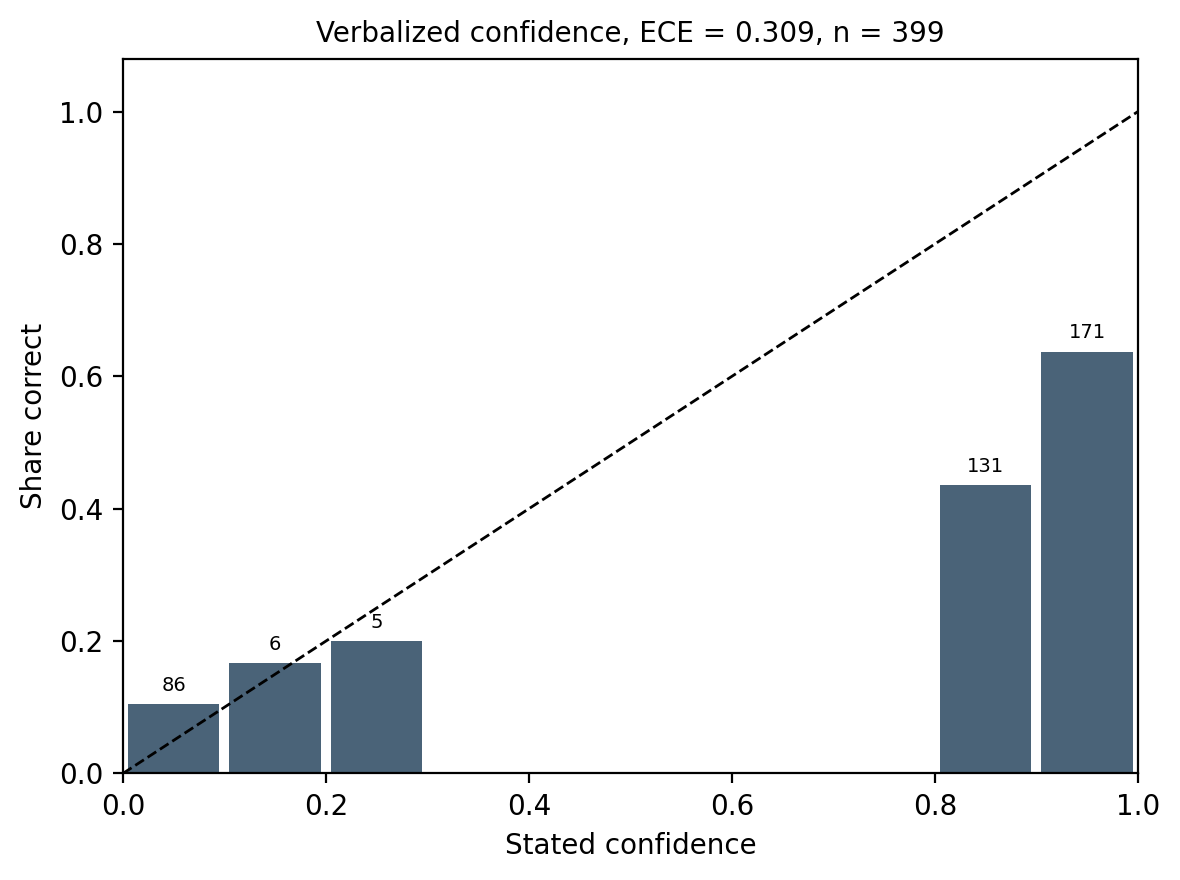

Most common stated values: [(100, 161), (85, 99), (0, 86), (80, 32), (90, 7), (10, 6)]


In [14]:
v = df[df.eligible & df.verbal.notna()]
bins = np.linspace(0, 1, 11)
band = np.clip(np.digitize(v.verbal.values, bins) - 1, 0, 9)
acc, conf, cnt = [], [], []
for b in range(10):
    m = band == b
    cnt.append(int(m.sum()))
    acc.append(float(v.correct.values[m].mean()) if m.any() else float("nan"))
    conf.append(float(v.verbal.values[m].mean()) if m.any() else float("nan"))
ece = sum(c / len(v) * abs(a - cf) for a, cf, c in zip(acc, conf, cnt) if c > 0)
fig, ax = plt.subplots(figsize=(6, 4.5), dpi=200)
ax.bar(bins[:-1] + 0.05, np.nan_to_num(acc), width=0.09, color="#4a6378")
ax.plot([0, 1], [0, 1], color="black", lw=1, ls="--")
for x, a, c in zip(bins[:-1] + 0.05, acc, cnt):
    if c:
        ax.text(x, (a if a == a else 0) + 0.02, str(c), ha="center", fontsize=7)
ax.set_xlabel("Stated confidence"); ax.set_ylabel("Share correct")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.08)
ax.set_title(f"Verbalized confidence, ECE = {ece:.3f}, n = {len(v)}", fontsize=10)
fig.tight_layout()
fig.savefig("reliability_verbalized.png", facecolor="white")
plt.show()
print("Most common stated values:", collections.Counter((v.verbal * 100).round().astype(int)).most_common(6))

### Does the correctness rule change the picture?

The same comparison with exact match instead of token F1 at least 0.5.

In [15]:
df_em = df.copy()
df_em["wrong"] = df_em["wrong_em"]
display(pd.DataFrame([{"Policy": p, "Coverage": f"{m['coverage']:.0%}", "Wrong among released (exact match)": f"{m['risk']:.1%}"}
                      for p, m in all_policies(df_em).items() if "unanswerable" not in p]))

,Policy,Coverage,Wrong among released (exact match)
0,Always answer,100%,62.4%
1,Token probability gate,50%,51.0%
2,Verbalized confidence gate,50%,46.7%
3,Sample agreement gate,50%,49.6%
4,Semantic entropy gate,50%,49.2%
5,Support self-check gate,50%,37.7%
6,Oracle (knows which questions have an answer),50%,25.0%


## Ambiguous questions. Ask, not decline

For each ambiguous question the gates use the score at which they released half of the SQuAD questions. The table shows what each gate does and which reading a released answer picks.

Using the two clarified readings, the uncertainty in the samples splits into a **within-reading** part (the model is unsure even after clarification, which points to decline) and a **between-reading** part (the readings lead to different answers, which points to ask). With a reading probability of one half each, total = entropy of the pooled answers, within = mean entropy inside each reading, and between = total minus within, the mutual information between reading and answer. This is the Shannon form of the split in Hou et al. (2024).

In [16]:
def reading_of(text, readings):
    hits = [rd["label"] for rd in readings
            if any(f" {normalize_answer(g)} " in f" {normalize_answer(text)} " for g in rd["golds"] if normalize_answer(g))]
    return "declined" if is_no_answer(text) else ("both" if len(hits) == 2 else (hits[0] if hits else "neither"))

k_half = int(round(TARGET_COVERAGE * len(df)))
cut = {}
for name, col in SIGNALS.items():
    s = np.where(np.isnan(df[col].values), -np.inf, df[col].values)[df.eligible.values]
    cut[name] = np.sort(s)[::-1][min(k_half, len(s)) - 1]
AB = "prompt allowing 'unanswerable'"

amb_rows, split_rows = [], []
for r in (r for r in RECS if r["set"] == "ambig"):
    row = item_row(r)
    out = {"id": r["id"], "question": r["question"], "answer": r["forced"],
           "reading picked": reading_of(r["forced"], r["readings"]),
           AB: reading_of(r["abstain"], r["readings"])}
    for name, col in SIGNALS.items():
        val = row[col]
        out[name] = "release" if (row["eligible"] and not np.isnan(val) and val >= cut[name]) else "withhold"
    amb_rows.append(out)
    pooled = r["readings"][0]["samples"] + r["readings"][1]["samples"]
    labels, _ = overlap_clusters(pooled)
    la, lb = labels[:len(r["readings"][0]["samples"])], labels[len(r["readings"][0]["samples"]):]
    h_total = entropy_bits(list(collections.Counter(labels).values()))
    h_within = 0.5 * entropy_bits(list(collections.Counter(la).values())) + \
               0.5 * entropy_bits(list(collections.Counter(lb).values()))
    split_rows.append({"id": r["id"], "entropy of original question": round(sample_entropy(r["samples"]), 3),
                       "total": round(h_total, 3), "within readings": round(h_within, 3),
                       "between readings": round(h_total - h_within, 3),
                       "clarified answers correct": sum(best_f1(rd["forced"], rd["golds"]) >= 0.5 for rd in r["readings"])})
amb = pd.DataFrame(amb_rows)
splits = pd.DataFrame(split_rows)
display(amb)
display(splits)
for name in SIGNALS:
    rel = amb[amb[name] == "release"]
    print(f"{name} gate released {len(rel)} of {len(amb)} ambiguous questions; "
          f"{int(rel['reading picked'].isin(['A', 'B']).sum())} of those answers silently picked one reading")
n_declined = int((amb[AB] == "declined").sum())
print(f"The prompt that allows 'unanswerable' declined {n_declined} of {len(amb)}")
print(f"Mean bits. Original question {splits['entropy of original question'].mean():.3f}, "
      f"within readings {splits['within readings'].mean():.3f}, between readings {splits['between readings'].mean():.3f}")

,id,question,answer,reading picked,prompt allowing 'unanswerable',Token probability,Verbalized confidence,Sample agreement,Semantic entropy,Support self-check
0,a01,Which room is the workshop in?,Room 204,A,A,release,withhold,release,release,release
1,a02,What time does the workshop start?,Friday 14:00,A,A,withhold,release,release,release,release
2,a03,What time does the library open?,North Library opens at 09:00,A,A,release,release,withhold,withhold,release
3,a04,Which platform does the train to Pittsburgh le...,platform 3,A,A,release,withhold,release,release,release
4,a05,When is the midterm?,October 14,A,A,release,withhold,withhold,withhold,withhold
5,a06,What day are office hours held?,Tuesday,A,A,release,release,withhold,withhold,withhold
6,a07,How often does the bus run on weekdays?,15 minutes,A,A,withhold,withhold,withhold,withhold,release
7,a08,How much does a ticket for the concert cost?,$14,B,B,release,release,release,release,withhold
8,a09,When is the deadline?,September 20 and December 12,both,both,release,release,release,release,release
9,a10,What time does the café close?,6 pm,A,A,release,release,release,release,release


,id,entropy of original question,total,within readings,between readings,clarified answers correct
0,a01,-0.000,-0.000,-0.000,0.000,2
1,a02,-0.000,1.000,-0.000,1.000,2
2,a03,0.469,1.000,-0.000,1.000,2
3,a04,-0.000,-0.000,-0.000,0.000,2
4,a05,0.722,1.000,-0.000,1.000,2
5,a06,0.469,1.000,-0.000,1.000,2
6,a07,0.722,0.722,0.485,0.236,2
7,a08,-0.000,1.000,-0.000,1.000,2
8,a09,-0.000,1.000,-0.000,1.000,2
9,a10,-0.000,-0.000,-0.000,0.000,2


Token probability gate released 9 of 12 ambiguous questions; 8 of those answers silently picked one reading
Verbalized confidence gate released 7 of 12 ambiguous questions; 6 of those answers silently picked one reading
Sample agreement gate released 6 of 12 ambiguous questions; 5 of those answers silently picked one reading
Semantic entropy gate released 6 of 12 ambiguous questions; 5 of those answers silently picked one reading
Support self-check gate released 8 of 12 ambiguous questions; 7 of those answers silently picked one reading
The prompt that allows 'unanswerable' declined 1 of 12
Mean bits. Original question 0.368, within readings 0.040, between readings 0.603


### Optional. The same split with a density matrix

This repeats the split with the kernel construction from the tutorial. Each sampled answer is embedded (all-mpnet-base-v2), an RBF kernel with γ = 1 gives a Gram matrix K, and ρ = K / tr(K) has the same nonzero eigenvalues as the density matrix of the answers. The split is total = S(mixture of both readings), within = mean of S(ρ) per reading, between = total minus within, which is the Holevo quantity. With short answers that share no meaning across readings, it should match the Shannon split above. This cell needs `sentence-transformers` and is skipped if it is missing.

In [17]:
def vn_entropy_bits(gram):
    lam = np.linalg.eigvalsh(gram / np.trace(gram))
    lam = lam[lam > 1e-12]
    return float(-(lam * np.log2(lam)).sum())

try:
    from sentence_transformers import SentenceTransformer
    emb_model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")
    spec_rows = []
    for r in (r for r in RECS if r["set"] == "ambig"):
        sa, sb = r["readings"][0]["samples"], r["readings"][1]["samples"]
        e = emb_model.encode(sa + sb, normalize_embeddings=True)
        for gamma in (1.0, 10.0):
            sq = np.sum((e[:, None, :] - e[None, :, :]) ** 2, axis=-1)
            K = np.exp(-gamma * sq)
            na = len(sa)
            s_total = vn_entropy_bits(K)
            s_within = 0.5 * vn_entropy_bits(K[:na, :na]) + 0.5 * vn_entropy_bits(K[na:, na:])
            spec_rows.append({"id": r["id"], "gamma": gamma, "total": round(s_total, 3),
                              "within": round(s_within, 3), "between (Holevo)": round(s_total - s_within, 3)})
    spec = pd.DataFrame(spec_rows)
    display(spec)
    print(spec.groupby("gamma")[["total", "within", "between (Holevo)"]].mean().round(3))
except ImportError:
    print("sentence-transformers is not installed. Run  !pip install -q sentence-transformers  and rerun this cell.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,id,gamma,total,within,between (Holevo)
0,a01,1.0,0.489,-0.000,0.489
1,a01,10.0,0.994,-0.000,0.994
2,a02,1.0,1.103,0.484,0.619
3,a02,10.0,1.581,0.595,0.985
4,a03,1.0,0.638,-0.000,0.638
5,a03,10.0,1.000,-0.000,1.000
6,a04,1.0,0.606,-0.000,0.606
7,a04,10.0,0.999,-0.000,0.999
8,a05,1.0,0.827,0.179,0.647
9,a05,10.0,1.200,0.234,0.966


       total  within  between (Holevo)
gamma                                 
1.0    0.758    0.16             0.597
10.0   1.182    0.19             0.991


## Workshop notice. Class against model

The model's answers to the six worksheet questions. Questions 5 and 6 have no answer in the notice.

In [18]:
ws = []
for r in sorted((r for r in RECS if r["set"] == "workshop"), key=lambda r: r["id"]):
    ws.append({"Question": r["label"], "Gold": ", ".join(r["golds"][:1]) or "not stated",
               "Always-answer reply": r["forced"],
               "Stated confidence": "" if r["verbal"] is None else f"{r['verbal']:.0%}",
               "Sample agreement": f"{agreement(r['forced'], r['samples']):.0%}",
               "Support P(Yes)": f"{r['support_p_yes']:.2f}",
               "Reply when 'unanswerable' is allowed": r["abstain"]})
ws_table = pd.DataFrame(ws)
display(ws_table)

,Question,Gold,Always-answer reply,Stated confidence,Sample agreement,Support P(Yes),Reply when 'unanswerable' is allowed
0,Coding room?,204,Room 204,100%,100%,1.00,Room 204
1,Design room?,310,Room 310,100%,100%,1.00,Room 310
2,Coding start time?,14:00,14:00,100%,100%,1.00,14:00
3,Design start time?,16:00,16:00,100%,100%,1.00,16:00
4,Attendance fee?,not stated,Registration required. Bring a laptop,0%,80%,0.00,unanswerable
5,Coding end time?,not stated,Friday 14:00,0%,100%,0.01,Friday 14:00


Fill in the class tallies after the activity and run the cell. For each question, count how many people wrote an answer, how many wrote that the notice does not say, and the average confidence of those who answered.

In [19]:
CLASS_TALLY = {              # label: (answered, declined, mean confidence of those who answered, 0 to 100)
    "Coding room?":       (0, 0, None),
    "Design room?":       (0, 0, None),
    "Coding start time?": (0, 0, None),
    "Design start time?": (0, 0, None),
    "Attendance fee?":    (0, 0, None),
    "Coding end time?":   (0, 0, None),
}

labels = list(CLASS_TALLY)
if sum(a + d for a, d, _ in CLASS_TALLY.values()) == 0:
    print("No class tallies entered yet.")
else:
    class_decl = [d / (a + d) if a + d else np.nan for a, d, _ in CLASS_TALLY.values()]
    by_label = {r["label"]: r for r in RECS if r["set"] == "workshop"}
    model_decl = [float(is_no_answer(by_label[l]["abstain"])) for l in labels]
    class_conf = [c / 100 if c is not None else np.nan for _, _, c in CLASS_TALLY.values()]
    model_conf = [by_label[l]["verbal"] if by_label[l]["verbal"] is not None else np.nan for l in labels]
    x = np.arange(len(labels))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=200)
    axes[0].bar(x - 0.2, class_decl, 0.4, label="Class", color="#4a6378")
    axes[0].bar(x + 0.2, model_decl, 0.4, label="Model, 'unanswerable' allowed", color="#c8a46a")
    axes[0].set_title("Share that declined", fontsize=10)
    axes[1].bar(x - 0.2, class_conf, 0.4, label="Class, mean of those who answered", color="#4a6378")
    axes[1].bar(x + 0.2, model_conf, 0.4, label="Model, always-answer reply", color="#c8a46a")
    axes[1].set_title("Stated confidence", fontsize=10)
    for a in axes:
        a.set_xticks(x); a.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)
        a.set_ylim(0, 1.05); a.legend(fontsize=7, frameon=False)
    fig.tight_layout()
    fig.savefig("class_vs_model.png", facecolor="white")
    plt.show()

No class tallies entered yet.


## Numbers for the slides

In [20]:
summary = {
    "model": META.get("model"), "dtype": META.get("dtype"), "device": META.get("device"),
    "n_squad": len(df), "n_answerable": n_ans, "target_coverage": TARGET_COVERAGE,
    "always_answer_correct_on_answerable": float(df[df.answerable].correct.mean()),
    "answered_without_answer": float(df[~df.answerable].eligible.mean()),
    "matched_distractor": float(df[~df.answerable].matches_distractor.mean()),
    "policies": {p: {**m, "risk_ci": list(ci(p, "risk"))} for p, m in point.items()},
    "quality": quality, "held_out": held,
    "ambiguous": {"n": len(amb),
                  "released": {n: int((amb[n] == "release").sum()) for n in SIGNALS},
                  "released_one_reading": {n: int(((amb[n] == "release") & amb["reading picked"].isin(["A", "B"])).sum())
                                           for n in SIGNALS},
                  "abstain_prompt_declined": n_declined,
                  "mean_bits": splits[["entropy of original question", "within readings", "between readings"]].mean().round(3).to_dict()},
}
json.dump(summary, open("summary.json", "w"), indent=2)
main_table.to_csv("slide_table.csv", index=False)
print(main_table.to_string(index=False))
print("\nSaved summary.json, slide_table.csv, risk_coverage.png, reliability_verbalized.png")

                                       Policy Coverage Wrong among released Correct answers withheld Answerable declined
                                Always answer     100% 55.6% [50.7%, 60.6%]                     0.0%                0.0%
                       Token probability gate      50% 46.0% [39.0%, 53.0%]                    39.0%               43.0%
                   Verbalized confidence gate      50% 38.9% [32.1%, 45.4%]                    31.0%               33.2%
                        Sample agreement gate      50% 41.6% [35.4%, 48.1%]                    34.0%               39.5%
                        Semantic entropy gate      50% 41.5% [35.2%, 47.7%]                    33.9%               39.4%
                      Support self-check gate      50% 26.8% [20.1%, 34.2%]                    17.3%               18.3%
                 Prompt allows 'unanswerable'      91% 51.8% [46.3%, 57.2%]                     0.0%                0.0%
Oracle (knows which questions ha

## Limits of this demo

* One small model, one prompt wording, and 400 questions. The intervals above show how much the numbers move with the sample.
* Correctness uses token F1 at least 0.5 against SQuAD gold answers. The exact-match check above shows whether the ranking of gates depends on that choice.
* Semantic entropy groups answers by word overlap, not by the entailment model used by Farquhar et al. (2024).
* The support self-check is the same model judging its own passage. It is not the separate autorater of Joren et al. (2025).
* The ambiguous questions were written for this demo and the clarified readings were written by hand. ICE (Hou et al., 2024) generates clarifications with a model.

**References**

* Geifman, Y., & El-Yaniv, R. (2017). Selective classification for deep neural networks. NeurIPS 30.
* Rajpurkar, P., Jia, R., & Liang, P. (2018). Know what you don't know. Unanswerable questions for SQuAD. ACL 2018.
* Xiong, M., et al. (2024). Can LLMs express their uncertainty? An empirical evaluation of confidence elicitation in LLMs. ICLR 2024.
* Farquhar, S., Kossen, J., Kuhn, L., & Gal, Y. (2024). Detecting hallucinations in large language models using semantic entropy. Nature, 630, 625–630.
* Hou, B., et al. (2024). Decomposing uncertainty for large language models through input clarification ensembling. ICML 2024, PMLR 235.
* Joren, H., et al. (2025). Sufficient context. A new lens on retrieval augmented generation systems. ICLR 2025.
* Nikitin, A., Kossen, J., Gal, Y., & Marttinen, P. (2024). Kernel language entropy. NeurIPS 37.
* Walha, N., et al. (2026). Fine-grained uncertainty decomposition in large language models. A spectral approach. AAAI 2026.
* Yang, A., et al. (2024). Qwen2.5 technical report. arXiv:2412.15115.